# 06 — Wasserstein NMF on the simulated catalogues

Same task as `05` (recover signatures $W$ and exposures $H$ from the counts $X$), but the KL loss is replaced by an **optimal-transport loss** with a ground cost $C$ over the 96 channels from `03` (graph) or `04` (linear combination).

**Model.** Each sample is normalised to a probability vector $a_j = x_j / \lVert x_j \rVert_1$ (as in the report, Section 3.2.1). The columns of $W$ and $H$ stay on the simplex, so $W h_j$ is also a probability vector, and

$$\min_{W, H} \; \frac{1}{m}\sum_{j=1}^{m} \omega_j \; \mathrm{OT}_\varepsilon\big(a_j,\; W h_j\big), \qquad \mathrm{OT}_\varepsilon(a,b) = \langle T^\star_\varepsilon, C \rangle,$$

where $T^\star_\varepsilon$ is the entropic transport plan (Sinkhorn) and $C$ is scaled to max 1.

**Solver.**
- *Gradient.* The gradient of $\mathrm{OT}_\varepsilon(a, b)$ with respect to $b$ is the Sinkhorn dual potential $g = \varepsilon \log v$, up to a constant (Cuturi & Doucet, 2014). So with $G = [g_1, \dots, g_m]$: $\nabla_H = W^\top G$ and $\nabla_W = G H^\top$.
- *Updates.* Alternating **mirror descent** (exponentiated gradient) on the simplex: $H \leftarrow H \odot e^{-\eta \nabla_H / \lVert\nabla_H\rVert_\infty}$, then renormalise each column; the same for $W$. This keeps everything positive and on the simplex, with no projection.
- *Speed.* All $m$ Sinkhorn problems share $K = e^{-C/\varepsilon}$ and run as one batched matrix scaling. The scalings are warm-started across iterations, so only a few Sinkhorn steps are needed per update.
- *Alternative.* Rolet, Cuturi & Peyré (2016) solve the same problem exactly through its dual. Mirror descent is used here because it is short, transparent and needs only numpy.

**Sample weights $\omega_j$.** Normalising every sample to sum 1 gives a 20-mutation profile the same weight as a 1,000-mutation one. KL-NMF weights samples by their counts implicitly. Without weights, the noisy low-burden samples dominate and recovery is much worse (see §4). The default `SAMPLE_WEIGHT = "burden"` uses $\omega_j \propto \lVert x_j\rVert_1$; `"sqrt"` and `"uniform"` are available.

**Exposures in counts.** $H$ is fitted as proportions; for evaluation it is multiplied by each sample's burden, which gives the same units as `H_true` and the KL-NMF exposures.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Resolve data/ whether the notebook is run from the repo root or a subfolder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
SIM = next((p for p in [ROOT / "simulated_data", DATA / "simulated_data"] if p.is_dir()), None)
assert SIM is not None, "simulated_data/ not found: run 02a_simulate_data_oldReport_method.ipynb first"
COST_DIR = DATA / "cost_matrix"
KLNMF = ROOT / "results" / "klnmf"
OUT = ROOT / "results" / "wnmf"
OUT.mkdir(parents=True, exist_ok=True)

SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
BASES = ["A", "C", "G", "T"]
CHANNELS = pd.Index([f"{f}[{s}]{t}" for s in SUBS for f in BASES for t in BASES], name="MutationType")
SUB_OF = CHANNELS.str[2:5].to_numpy(dtype=str)

available = sorted(p.stem.removeprefix("C_").removesuffix("_scaled") for p in COST_DIR.glob("C_*_scaled.csv"))
print("cost matrices available:", available)

cost matrices available: ['graph_data', 'graph_energy', 'graph_struct', 'lin_hamming', 'lin_tstv', 'linear']


## 1. Parameters

In [2]:
N_SIGNATURES_LIST = [8, 15, 25]
NOISE_LEVELS = [0.02, 0.04, 0.06]
DETAIL = (15, 0.04)                      # dataset examined in detail, as in 05
DETAIL_COST = "graph_struct"             # cost used for the detailed fit
BENCH_COSTS = ["lin_hamming", "graph_struct"]  # costs run in the benchmark (any name from `available`)

EPS = 0.01              # entropic regularisation (cost scaled to max 1); smaller = sharper but slower Sinkhorn
ETA = 0.1               # mirror-descent step (relative to the largest gradient entry)
N_SINK = 10             # Sinkhorn iterations per update (warm-started)
MAX_ITER = 2000         # outer iterations (one H step + one W step each)
TOL = 1e-4              # stop when the best loss has improved by less than TOL (relative) over the last PATIENCE iterations
PATIENCE = 200
MIN_ITER = 300          # never stop before this (early loss estimates are noisy while Sinkhorn warms up)
SAMPLE_WEIGHT = "burden"  # "burden" | "sqrt" | "uniform"
N_RESTARTS = 3          # random initialisations per fit; the lowest loss is kept
INIT_FROM_KLNMF = False # True: also try one run warm-started from the 05 solution ("refine KL-NMF");
                        # keep False for an independent comparison in 07
SEED = 2025
COS_GOOD = 0.9

## 2. Data and solver

In [3]:
def tag(k, noise):
    return f"k{k}_noise{int(round(noise * 100))}pct"


def load(k, noise):
    t = tag(k, noise)
    X = pd.read_csv(SIM / f"X_{t}.csv", index_col=0)
    W = pd.read_csv(SIM / f"W_true_{t}.csv", index_col=0)
    H = pd.read_csv(SIM / f"H_true_{t}.csv", index_col=0)
    return X.loc[CHANNELS], W.loc[CHANNELS], H


def load_cost(name):
    return pd.read_csv(COST_DIR / f"C_{name}_scaled.csv", index_col=0).loc[CHANNELS, CHANNELS].values


def load_klnmf(k, noise):
    t = tag(k, noise)
    if not (KLNMF / f"W_{t}.csv").exists():
        return None
    W = pd.read_csv(KLNMF / f"W_{t}.csv", index_col=0).loc[CHANNELS]
    H = pd.read_csv(KLNMF / f"H_{t}.csv", index_col=0)
    return W.values, H.values


def sample_weights(X, how=SAMPLE_WEIGHT):
    tot = np.asarray(X, float).sum(0)
    w = {"burden": tot, "sqrt": np.sqrt(tot), "uniform": np.ones_like(tot)}[how]
    return w / w.mean()

In [4]:
def wnmf(X, C, K, eps=EPS, eta=ETA, n_sink=N_SINK, max_iter=MAX_ITER, tol=TOL, patience=PATIENCE, min_iter=MIN_ITER, weights=SAMPLE_WEIGHT,
         rng=None, W0=None, H0=None, fix_W=False):
    # Wasserstein NMF by alternating mirror descent; returns W (96 x K, columns on simplex), H (K x m, proportions)
    X = np.asarray(X, float)
    A = X / X.sum(0)
    n, m = A.shape
    rng = np.random.default_rng(rng)
    Kmat = np.exp(-C / eps)
    KC = Kmat * C
    W = (rng.random((n, K)) + 0.1) if W0 is None else np.asarray(W0, float).copy()
    H = (rng.random((K, m)) + 0.1) if H0 is None else np.asarray(H0, float).copy() + 1e-6
    W /= W.sum(0); H /= H.sum(0)
    w = sample_weights(X, weights)
    v = np.ones((n, m))
    losses = []
    for it in range(max_iter):
        for step in ("H", "W"):
            if step == "W" and fix_W:
                continue
            B = W @ H
            for _ in range(n_sink):
                u = A / (Kmat @ v)
                v = B / (Kmat.T @ u)
            G = eps * np.log(v + 1e-300)
            G = (G - G.mean(0, keepdims=True)) * w[None, :]
            if step == "H":
                g = W.T @ G
                H = H * np.exp(-eta * g / (np.abs(g).max() + 1e-12)); H /= H.sum(0)
            else:
                g = G @ H.T / m
                W = W * np.exp(-eta * g / (np.abs(g).max() + 1e-12)); W /= W.sum(0)
        if it % 50 == 0 or it == max_iter - 1:
            losses.append(float(np.sum(w * np.sum(u * (KC @ v), 0)) / m))
            n_back = patience // 50
            if it >= min_iter and len(losses) > n_back:
                before, recent = min(losses[:-n_back]), min(losses[-n_back:])
                if (before - recent) / before < tol:
                    break
    return W, H, np.array(losses), it + 1


def fit(X, C, K, n_restarts=N_RESTARTS, seed=SEED, klnmf_init=None, **kw):
    runs = []
    for r in range(n_restarts):
        W, H, losses, n_it = wnmf(X, C, K, rng=seed + r, **kw)
        runs.append(dict(init=f"random {r}", W=W, H=H, losses=losses, n_iter=n_it, loss=losses[-1]))
    if klnmf_init is not None:
        W, H, losses, n_it = wnmf(X, C, K, W0=klnmf_init[0], H0=klnmf_init[1], **kw)
        runs.append(dict(init="KL-NMF", W=W, H=H, losses=losses, n_iter=n_it, loss=losses[-1]))
    best = min(runs, key=lambda d: d["loss"])
    return best, runs


def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B


def match(W_est, W_ref):
    S = cosine_matrix(np.asarray(W_ref), np.asarray(W_est))
    r, c = linear_sum_assignment(-S)
    return pd.DataFrame({"true": np.asarray(W_ref.columns)[r], "est_col": c, "cosine": S[r, c]})

## 3. Detailed fit

K=15, cost=graph_struct: 3 runs in 34.1s; best = random 0 (loss 0.00687, 2000 iterations)


loss with the true W (H refitted): 0.00919


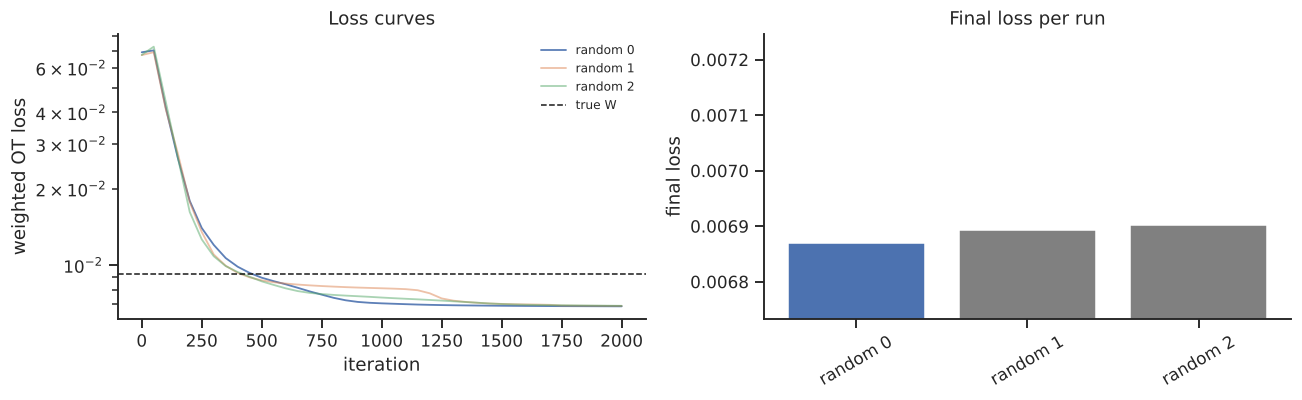

In [5]:
X, W_true, H_true = load(*DETAIL)
K = W_true.shape[1]
C = load_cost(DETAIL_COST)
t0 = time.time()
best, runs = fit(X, C, K, klnmf_init=load_klnmf(*DETAIL) if INIT_FROM_KLNMF else None)
print(f"K={K}, cost={DETAIL_COST}: {len(runs)} runs in {time.time() - t0:.1f}s; best = {best['init']} "
      f"(loss {best['loss']:.5f}, {best['n_iter']} iterations)")

# reference: the loss of the true signatures, with H refitted under the same loss
_, _, l_true, _ = wnmf(X, C, K, W0=W_true.values, H0=H_true.values, fix_W=True, max_iter=500)
print(f"loss with the true W (H refitted): {l_true[-1]:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for d in runs:
    axes[0].plot(np.arange(len(d["losses"])) * 50, d["losses"], lw=1.2, label=d["init"], alpha=0.9 if d is best else 0.5)
axes[0].axhline(l_true[-1], c="k", ls="--", lw=1, label="true W")
axes[0].set(yscale="log", xlabel="iteration", ylabel="weighted OT loss", title="Loss curves")
axes[0].legend(frameon=False, fontsize=8)
axes[1].bar([d["init"] for d in runs], [d["loss"] for d in runs], color=["C0" if d is best else "grey" for d in runs])
axes[1].set(ylabel="final loss", title="Final loss per run", ylim=(min(d["loss"] for d in runs) * 0.98, None))
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

In [6]:
totals = X.sum().values
m = match(best["W"], W_true)
W_est = pd.DataFrame(best["W"][:, m.est_col], index=CHANNELS, columns=m.true)
H_est = pd.DataFrame(best["H"][m.est_col] * totals, index=m.true, columns=X.columns)   # proportions -> counts

m["exposure r"] = [np.corrcoef(H_est.loc[s], H_true.loc[s])[0, 1] for s in m.true]
print(f"mean cosine {m.cosine.mean():.3f}; recovered (cos ≥ {COS_GOOD}): {(m.cosine >= COS_GOOD).sum()}/{K}")
m.sort_values("cosine").drop(columns="est_col").round(3)

mean cosine 0.969; recovered (cos ≥ 0.9): 14/15


,true,cosine,exposure r
12,SBS3,0.782,0.818
14,SBS93,0.937,0.949
2,SBS39,0.947,0.954
7,SBS54,0.949,0.988
8,SBS87,0.975,0.991
0,SBS98,0.983,0.933
5,SBS96,0.984,0.973
6,SBS37,0.989,0.985
11,SBS99,0.992,0.978
1,SBS86,0.994,0.987


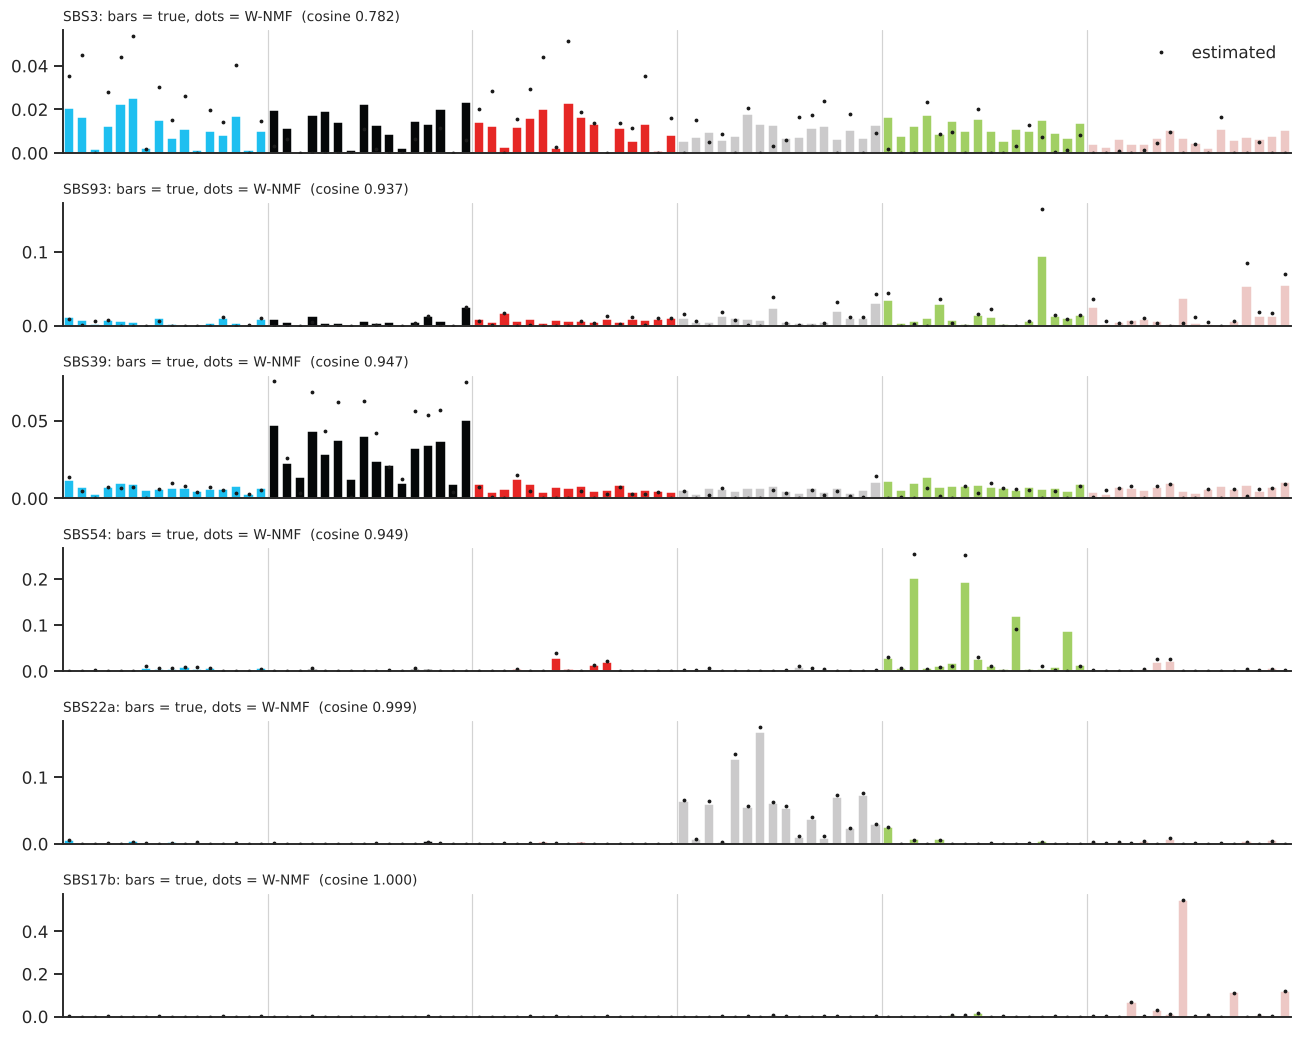

In [7]:
def plot_pair(ax, w_true, w_est, title):
    x = np.arange(96)
    ax.bar(x, w_true, color=[SUB_COLORS[s] for s in SUB_OF], width=0.8)
    ax.plot(x, w_est, "k.", ms=3, label="estimated")
    for i in range(1, 6):
        ax.axvline(16 * i - 0.5, c="lightgrey", lw=0.8)
    ax.set_xlim(-0.5, 95.5); ax.set_xticks([])
    ax.set_title(title, fontsize=9, loc="left")

order = m.sort_values("cosine").true.tolist()
show = order[:4] + order[-2:]
fig, axes = plt.subplots(len(show), 1, figsize=(12, 1.6 * len(show)), sharex=True)
for ax, s in zip(axes, show):
    plot_pair(ax, W_true[s], W_est[s], f"{s}: bars = true, dots = W-NMF  (cosine {m.set_index('true').at[s, 'cosine']:.3f})")
axes[0].legend(frameon=False, loc="upper right")
plt.tight_layout()

## 4. Sensitivity: sample weights and ε

One random start each on the detailed dataset, to show which settings matter. (The benchmark below uses the parameter cell.)

In [8]:
sens = []
for how in ["uniform", "sqrt", "burden"]:
    for eps in [0.005, 0.01, 0.025]:
        W, H, l, n_it = wnmf(X, C, K, eps=eps, weights=how, rng=SEED)
        mk = match(W, W_true)
        sens.append(dict(weights=how, eps=eps, mean_cos=mk.cosine.mean(), recovered=(mk.cosine >= COS_GOOD).sum(), iters=n_it))
sens = pd.DataFrame(sens)
sens.pivot(index="weights", columns="eps", values="mean_cos").round(3)

eps,0.005,0.010,0.025
weights,,,
burden,0.954,0.969,0.958
sqrt,0.961,0.916,0.916
uniform,0.910,0.906,0.927


## 5. Benchmark over the 9 simulated conditions

For every cost in `BENCH_COSTS`, K set to the true number of signatures. Takes several minutes; reduce `N_RESTARTS` or `MAX_ITER` for a quicker pass.

In [9]:
bench, fits = [], {}
t0 = time.time()
for cost in BENCH_COSTS:
    Cc = load_cost(cost)
    for k in N_SIGNATURES_LIST:
        for noise in NOISE_LEVELS:
            Xk, Wk, Hk = load(k, noise)
            b, _ = fit(Xk, Cc, k, klnmf_init=load_klnmf(k, noise) if INIT_FROM_KLNMF else None)
            mk = match(b["W"], Wk)
            He = b["H"][mk.est_col] * Xk.sum().values
            fits[(cost, k, noise)] = (b, mk, He)
            bench.append(dict(cost=cost, k=k, noise=noise, mean_cos=mk.cosine.mean(), min_cos=mk.cosine.min(),
                              recovered=f"{(mk.cosine >= COS_GOOD).sum()}/{k}",
                              exposure_r=np.mean([np.corrcoef(He[i], Hk.loc[s])[0, 1] for i, s in enumerate(mk.true)]),
                              loss=b["loss"], best_init=b["init"], iters=b["n_iter"]))
        print(f"{cost}: done after {time.time() - t0:.0f}s")
bench = pd.DataFrame(bench)
bench.round(3)

lin_hamming: done after 99s


lin_hamming: done after 201s


lin_hamming: done after 304s


graph_struct: done after 407s


graph_struct: done after 510s


graph_struct: done after 611s


,cost,k,noise,mean_cos,min_cos,recovered,exposure_r,loss,best_init,iters
0,lin_hamming,8,0.02,0.993,0.966,8/8,0.993,0.013,random 2,2000
1,lin_hamming,8,0.04,0.992,0.957,8/8,0.992,0.016,random 0,2000
2,lin_hamming,8,0.06,0.991,0.950,8/8,0.992,0.018,random 0,2000
3,lin_hamming,15,0.02,0.974,0.828,13/15,0.972,0.011,random 0,2000
4,lin_hamming,15,0.04,0.976,0.803,14/15,0.974,0.013,random 1,2000
5,lin_hamming,15,0.06,0.977,0.820,14/15,0.968,0.014,random 0,2000
6,lin_hamming,25,0.02,0.931,0.716,18/25,0.920,0.010,random 2,2000
7,lin_hamming,25,0.04,0.925,0.631,18/25,0.895,0.011,random 0,2000
8,lin_hamming,25,0.06,0.915,0.404,19/25,0.873,0.012,random 1,2000
9,graph_struct,8,0.02,0.992,0.953,8/8,0.989,0.007,random 0,2000


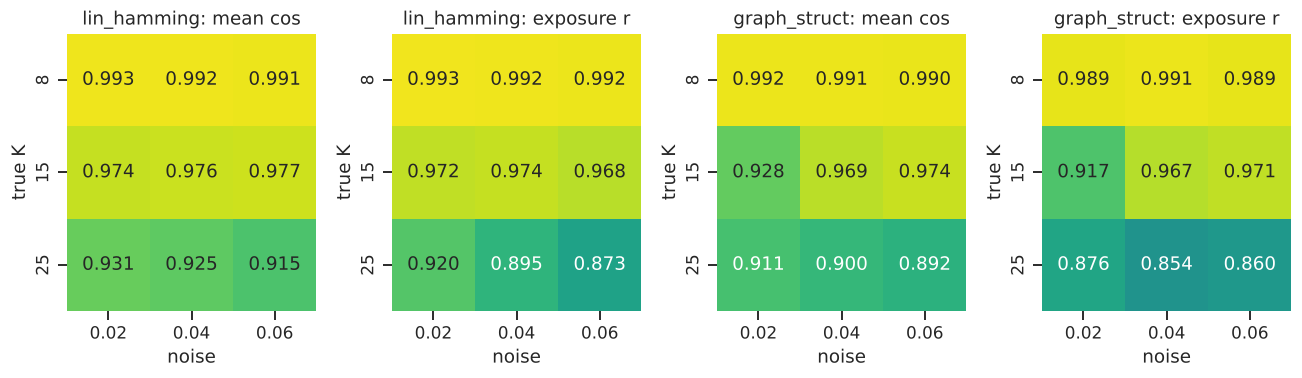

In [10]:
fig, axes = plt.subplots(1, 2 * len(BENCH_COSTS), figsize=(6 * len(BENCH_COSTS), 3.6), squeeze=False)
for i, cost in enumerate(BENCH_COSTS):
    b = bench[bench.cost == cost]
    for j, metric in enumerate(["mean_cos", "exposure_r"]):
        ax = axes[0, 2 * i + j]
        sns.heatmap(b.pivot(index="k", columns="noise", values=metric), ax=ax, annot=True, fmt=".3f",
                    cmap="viridis", vmin=0.7, vmax=1, cbar=False)
        ax.set(title=f"{cost}: {metric.replace('_', ' ')}", xlabel="noise", ylabel="true K")
plt.tight_layout()

## 6. Save

`results/wnmf/<cost>/`: `W_<tag>.csv` (matched to true signature names, canonical channel order), `H_<tag>.csv` (exposures in counts), `match_<tag>.csv`, plus `benchmark.csv` and `params.json` at the top level. `07` reads these together with `results/klnmf/`.

In [11]:
for (cost, k, noise), (b, mk, He) in fits.items():
    d = OUT / cost
    d.mkdir(exist_ok=True)
    t = tag(k, noise)
    pd.DataFrame(b["W"][:, mk.est_col], index=CHANNELS, columns=mk.true).to_csv(d / f"W_{t}.csv")
    pd.DataFrame(He, index=mk.true, columns=load(k, noise)[0].columns).to_csv(d / f"H_{t}.csv")
    mk.to_csv(d / f"match_{t}.csv", index=False)
bench.to_csv(OUT / "benchmark.csv", index=False)
(OUT / "params.json").write_text(json.dumps(dict(EPS=EPS, ETA=ETA, N_SINK=N_SINK, MAX_ITER=MAX_ITER, TOL=TOL, PATIENCE=PATIENCE, MIN_ITER=MIN_ITER,
                                                 SAMPLE_WEIGHT=SAMPLE_WEIGHT, N_RESTARTS=N_RESTARTS,
                                                 INIT_FROM_KLNMF=INIT_FROM_KLNMF, SEED=SEED, BENCH_COSTS=BENCH_COSTS), indent=2))
sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*.csv"))[:6]

['benchmark.csv',
 'graph_struct/H_k15_noise2pct.csv',
 'graph_struct/H_k15_noise4pct.csv',
 'graph_struct/H_k15_noise6pct.csv',
 'graph_struct/H_k25_noise2pct.csv',
 'graph_struct/H_k25_noise4pct.csv']